# OrbitWarsPolicy — Uçtan Uca Forward Walkthrough

Bu notebook bir **observation**'ı alır ve `OrbitWarsPolicy` ağındaki **her katmandan** sırayla geçirir.
Her adımda:
- giren / çıkan tensör shape'lerini,
- ufak bir sayısal örneği,
- katmanın **ne yaptığını** kısaca

gösterir. Sonunda `act()` ile aksiyon örnekler ve `decode_action` ile env aksiyonuna çeviririz.

## İçindekiler

1. Kurulum & repo path
2. Toy observation üretimi
3. Ağ mimarisinin görsel şeması
4. Modeli kurma & parametre dökümü
5. **Layer 1** — Input projeksiyonlar (`planet_proj`, `fleet_proj`, `global_proj`)
6. **Layer 2** — Token-type embedding
7. **Layer 3** — Edge projeksiyon → attention bias
8. **Layer 4** — Padding mask
9. **Layer 5** — Transformer blokları (her biri ayrı çalıştırılır)
10. **Layer 6** — Final LayerNorm
11. **Layer 7a** — `src_head` + NO-OP
12. **Layer 7b** — Pointer attention (`tgt_query`, `tgt_key`)
13. **Layer 7c** — `ship_head`
14. **Layer 7d** — `value_head`
15. `act()` ile örnekleme
16. `decode_action` ile env aksiyonu
17. Toplam shape özeti


## 1. Kurulum

In [1]:
from pathlib import Path
import sys

REPO = Path.cwd()
while REPO.name != 'Orbit_Wars' and REPO.parent != REPO:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
print('Repo root:', REPO)


Repo root: /Users/doruksarigun/Kaggle/orbit-wars/Orbit_Wars


In [2]:
import math
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

from obs_builder import (
    build_observation, decode_action,
    PLANET_FEATURE_DIM, FLEET_FEATURE_DIM, GLOBAL_FEATURE_DIM, EDGE_FEATURE_DIM,
    P_MAX_DEFAULT, F_MAX_DEFAULT,
)
from model import OrbitWarsPolicy, pack_observations

torch.manual_seed(0)
np.random.seed(0)


## 2. Toy Observation

Anlaması kolay olsun diye küçük bir `p_max=8`, `f_max=4` durumunu kullanıyoruz.
Default ağ `p_max=32, f_max=32` ile gelir; aynı modeli daha küçük bir kopya olarak yeniden kuracağız.

In [3]:
toy_state = {
    'planets': [
        [0,  0, 70.0, 70.0, 3.0, 100, 3],   # bizim, dolu (kaynak adayı)
        [1,  0, 80.0, 70.0, 2.0,  50, 2],   # bizim
        [2,  1, 30.0, 30.0, 2.0,  80, 2],   # düşman
        [3, -1, 20.0, 80.0, 2.0,  10, 1],   # neutral
    ],
    'fleets': [
        [10, 1, 60.0, 60.0, 0.0, 2, 25],     # düşman fleet uçuyor
    ],
    'initial_planets': [
        [0,  0, 70.0, 70.0, 3.0, 100, 3],
        [1,  0, 80.0, 70.0, 2.0,  50, 2],
        [2,  1, 30.0, 30.0, 2.0,  80, 2],
        [3, -1, 20.0, 80.0, 2.0,  10, 1],
    ],
    'comet_planet_ids': [],
    'comets': [],
}

P_MAX, F_MAX = 8, 4
obs = build_observation(toy_state, player=0, angular_velocity=0.05,
                        p_max=P_MAX, f_max=F_MAX)

print('planet_feats:', obs.planet_feats.shape)
print('fleet_feats :', obs.fleet_feats.shape)
print('global_feats:', obs.global_feats.shape)
print('edge_bias   :', obs.edge_bias.shape, '  T = P + F + 1 =', P_MAX + F_MAX + 1)
print('planet_mask :', obs.planet_mask.astype(int))
print('fleet_mask  :', obs.fleet_mask.astype(int))
print('source_mask :', obs.source_mask.astype(int))


planet_feats: (8, 15)
fleet_feats : (4, 11)
global_feats: (12,)
edge_bias   : (13, 13, 5)   T = P + F + 1 = 13
planet_mask : [1 1 1 1 0 0 0 0]
fleet_mask  : [1 0 0 0]
source_mask : [1 1 0 0 0 0 0 0]


In [4]:
# Observation listesi -> batch tensor dict
batch = pack_observations([obs])
for k, v in batch.items():
    print(f'{k:14s} {tuple(v.shape)}  dtype={v.dtype}')


planet_feats   (1, 8, 15)  dtype=torch.float32
fleet_feats    (1, 4, 11)  dtype=torch.float32
global_feats   (1, 12)  dtype=torch.float32
edge_bias      (1, 13, 13, 5)  dtype=torch.float32
planet_mask    (1, 8)  dtype=torch.bool
fleet_mask     (1, 4)  dtype=torch.bool
source_mask    (1, 8)  dtype=torch.bool


## 3. Ağın Mimari Şeması

Aşağıda tüm forward yolu — input projection'lardan dört aksiyon/value head'ine kadar — boxes-and-arrows
şeklinde çiziliyor. Renkler: mavi = input, yeşil = encoder, turuncu = head.

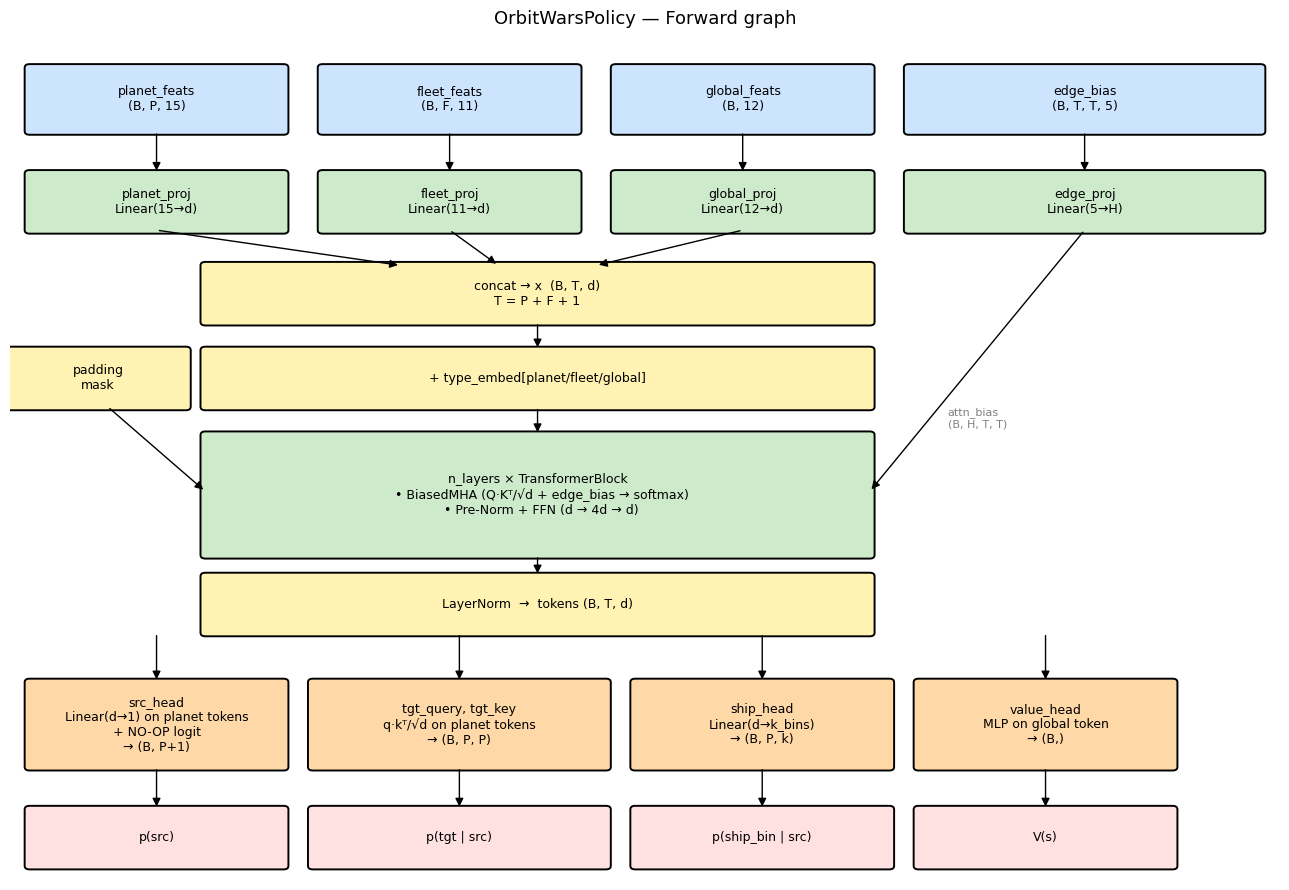

In [5]:
def draw_arch():
    fig, ax = plt.subplots(figsize=(13, 9))
    ax.set_xlim(0, 13); ax.set_ylim(0, 12); ax.axis('off')

    def box(x, y, w, h, text, color):
        r = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05',
                            linewidth=1.4, edgecolor='black', facecolor=color)
        ax.add_patch(r)
        ax.text(x + w/2, y + h/2, text, ha='center', va='center', fontsize=9)

    def arrow(x1, y1, x2, y2):
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2),
                                      arrowstyle='-|>', mutation_scale=12,
                                      linewidth=1, color='black'))

    BLUE   = '#cde4ff'
    GREEN  = '#cdeacb'
    YELLOW = '#fff2b3'
    ORANGE = '#ffd8a8'

    # Inputs
    box(0.2, 10.6, 2.6, 0.9, 'planet_feats\n(B, P, 15)', BLUE)
    box(3.2, 10.6, 2.6, 0.9, 'fleet_feats\n(B, F, 11)', BLUE)
    box(6.2, 10.6, 2.6, 0.9, 'global_feats\n(B, 12)', BLUE)
    box(9.2, 10.6, 3.6, 0.9, 'edge_bias\n(B, T, T, 5)', BLUE)

    # Per-token projections
    box(0.2, 9.2, 2.6, 0.8, 'planet_proj\nLinear(15→d)', GREEN)
    box(3.2, 9.2, 2.6, 0.8, 'fleet_proj\nLinear(11→d)', GREEN)
    box(6.2, 9.2, 2.6, 0.8, 'global_proj\nLinear(12→d)', GREEN)
    box(9.2, 9.2, 3.6, 0.8, 'edge_proj\nLinear(5→H)', GREEN)
    for x in [1.5, 4.5, 7.5, 11.0]:
        arrow(x, 10.6, x, 10.0)

    # Concat
    box(2.0, 7.9, 6.8, 0.8, 'concat → x  (B, T, d)\nT = P + F + 1', YELLOW)
    arrow(1.5, 9.2, 4.0, 8.7)
    arrow(4.5, 9.2, 5.0, 8.7)
    arrow(7.5, 9.2, 6.0, 8.7)

    # Type embed
    box(2.0, 6.7, 6.8, 0.8, '+ type_embed[planet/fleet/global]', YELLOW)
    arrow(5.4, 7.9, 5.4, 7.5)

    # Padding mask
    box(0.0, 6.7, 1.8, 0.8, 'padding\nmask', YELLOW)

    # Transformer blocks (n_layers x)
    box(2.0, 4.6, 6.8, 1.7,
        'n_layers × TransformerBlock\n  • BiasedMHA (Q·Kᵀ/√d + edge_bias → softmax)\n  • Pre-Norm + FFN (d → 4d → d)',
        GREEN)
    arrow(5.4, 6.7, 5.4, 6.3)
    # edge_bias enters MHA
    arrow(11.0, 9.2, 8.8, 5.5)
    ax.text(9.6, 6.4, 'attn_bias\n(B, H, T, T)', fontsize=8, color='gray')
    # padding mask enters MHA
    arrow(1.0, 6.7, 2.0, 5.5)

    # Final LayerNorm
    box(2.0, 3.5, 6.8, 0.8, 'LayerNorm  →  tokens (B, T, d)', YELLOW)
    arrow(5.4, 4.6, 5.4, 4.3)

    # Heads
    box(0.2, 1.6, 2.6, 1.2,
        'src_head\nLinear(d→1) on planet tokens\n+ NO-OP logit\n→ (B, P+1)', ORANGE)
    box(3.1, 1.6, 3.0, 1.2,
        'tgt_query, tgt_key\nq·kᵀ/√d on planet tokens\n→ (B, P, P)', ORANGE)
    box(6.4, 1.6, 2.6, 1.2,
        'ship_head\nLinear(d→k_bins)\n→ (B, P, k)', ORANGE)
    box(9.3, 1.6, 2.6, 1.2,
        'value_head\nMLP on global token\n→ (B,)', ORANGE)
    for x in [1.5, 4.6, 7.7, 10.6]:
        arrow(x, 3.5, x, 2.8)

    # action / value labels
    box(0.2, 0.2, 2.6, 0.8, 'p(src)', '#ffe1e1')
    box(3.1, 0.2, 3.0, 0.8, 'p(tgt | src)', '#ffe1e1')
    box(6.4, 0.2, 2.6, 0.8, 'p(ship_bin | src)', '#ffe1e1')
    box(9.3, 0.2, 2.6, 0.8, 'V(s)', '#ffe1e1')
    for x in [1.5, 4.6, 7.7, 10.6]:
        arrow(x, 1.6, x, 1.0)

    ax.set_title('OrbitWarsPolicy — Forward graph', fontsize=13)
    plt.tight_layout()
    plt.show()

draw_arch()


## 4. Modeli Kur ve Parametre Dökümünü Çıkar

In [6]:
net = OrbitWarsPolicy(
    p_max=P_MAX, f_max=F_MAX,
    d_model=64, n_heads=4, n_layers=2, n_ship_bins=5,
)
net.eval()

T = P_MAX + F_MAX + 1
H = net.n_heads
D = net.d_model
print(f'T = {T},  d_model = {D},  n_heads = {H},  d_head = {D//H}')

total = 0
for name, p in net.named_parameters():
    n = p.numel()
    total += n
    print(f'{name:40s} {tuple(p.shape)}  →  {n:>7,}')
print(f'\nTotal params: {total:,}')


T = 13,  d_model = 64,  n_heads = 4,  d_head = 16
noop_logit                               (1,)  →        1
planet_proj.weight                       (64, 15)  →      960
planet_proj.bias                         (64,)  →       64
fleet_proj.weight                        (64, 11)  →      704
fleet_proj.bias                          (64,)  →       64
global_proj.weight                       (64, 12)  →      768
global_proj.bias                         (64,)  →       64
type_embed.weight                        (3, 64)  →      192
edge_proj.weight                         (4, 5)  →       20
edge_proj.bias                           (4,)  →        4
blocks.0.norm1.weight                    (64,)  →       64
blocks.0.norm1.bias                      (64,)  →       64
blocks.0.attn.qkv.weight                 (192, 64)  →   12,288
blocks.0.attn.qkv.bias                   (192,)  →      192
blocks.0.attn.out_proj.weight            (64, 64)  →    4,096
blocks.0.attn.out_proj.bias              (64,) 

## 5. Layer 1 — Input Projeksiyonları

Üç farklı feature uzayı (15-d / 11-d / 12-d) tek bir `d_model`'e taşınır.
`Linear` katmanı = `x @ W + b`. LLM'deki `nn.Embedding`'in dense karşılığı.

In [7]:
planet_feats = batch['planet_feats']
fleet_feats  = batch['fleet_feats']
global_feats = batch['global_feats']

with torch.no_grad():
    planet_tok = net.planet_proj(planet_feats)               # (B, P, d)
    fleet_tok  = net.fleet_proj(fleet_feats)                  # (B, F, d)
    global_tok = net.global_proj(global_feats).unsqueeze(1)   # (B, 1, d)

print('planet_tok :', tuple(planet_tok.shape))
print('fleet_tok  :', tuple(fleet_tok.shape))
print('global_tok :', tuple(global_tok.shape))
print('\nplanet_tok[0, 0, :8] =', planet_tok[0, 0, :8].tolist())


planet_tok : (1, 8, 64)
fleet_tok  : (1, 4, 64)
global_tok : (1, 1, 64)

planet_tok[0, 0, :8] = [-0.430414617061615, 0.07089778035879135, -0.19346138834953308, -0.41691774129867554, 0.12093278765678406, -0.021747466176748276, 0.17346490919589996, -0.25117409229278564]


## 6. Layer 2 — Concat + Type Embedding

Tüm tokenlar tek diziye birleşir: `[planet_0..P-1, fleet_0..F-1, GLOBAL]`.
Sonra her tipe ait öğrenilebilir bir vektör eklenir (LLM'deki position embedding'in
ayrık-tip karşılığı).

In [8]:
with torch.no_grad():
    x_cat = torch.cat([planet_tok, fleet_tok, global_tok], dim=1)   # (B, T, d)
    type_emb = net.type_embed(net.type_ids)                          # (T, d)
    x = x_cat + type_emb[None]

print('x (concat)         :', tuple(x_cat.shape))
print('type_ids (ilk 12)  :', net.type_ids[:12].tolist())   # 0=planet, 1=fleet, 2=global
print('type_ids (son 5)   :', net.type_ids[-5:].tolist())
print('x (+type_embed)    :', tuple(x.shape))


x (concat)         : (1, 13, 64)
type_ids (ilk 12)  : [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1]
type_ids (son 5)   : [1, 1, 1, 1, 2]
x (+type_embed)    : (1, 13, 64)


## 7. Layer 3 — Edge Projection → Attention Bias

5-kanallı pairwise edge feature (`dist, dx, dy, sin Δφ, cos Δφ`) her **head** için
bir skaler bias'a indirilir. Bu bias `Q·Kᵀ/√d`'ye eklenip softmax'tan geçer.

`Linear(5 → H)` → `permute` ile `(B, H, T, T)`.

In [9]:
edge_bias = batch['edge_bias']
with torch.no_grad():
    eb = net.edge_proj(edge_bias)                  # (B, T, T, H)
    attn_bias = eb.permute(0, 3, 1, 2).contiguous()  # (B, H, T, T)

print('edge_bias  :', tuple(edge_bias.shape))
print('attn_bias  :', tuple(attn_bias.shape))
print('\nİlk head, ilk 6×6 alt-blok (planet-planet ilişkileri):')
print(attn_bias[0, 0, :6, :6].numpy().round(3))


edge_bias  : (1, 13, 13, 5)
attn_bias  : (1, 4, 13, 13)

İlk head, ilk 6×6 alt-blok (planet-planet ilişkileri):
[[-0.028 -0.308  0.094 -0.139  0.017  0.017]
 [-0.27  -0.028  0.105 -0.1    0.029  0.029]
 [-0.154 -0.235 -0.028 -0.124 -0.33  -0.33 ]
 [-0.327 -0.356 -0.341 -0.028 -0.375 -0.375]
 [-0.418 -0.498 -0.516 -0.344 -0.028 -0.253]
 [-0.418 -0.498 -0.516 -0.344 -0.253 -0.028]]


## 8. Layer 4 — Padding Mask

`planet_mask` ve `fleet_mask` gerçek tokenları işaret eder. Attention'a verilen
mask `True = PAD` konvansiyonunu kullanır.

In [10]:
with torch.no_grad():
    kpm = net._build_padding_mask(batch['planet_mask'], batch['fleet_mask'])

print('key_padding_mask :', tuple(kpm.shape))
print('PAD slot sayısı  :', int(kpm.sum().item()))
print('mask (ilk batch) :', kpm[0].int().tolist())


key_padding_mask : (1, 13)
PAD slot sayısı  : 7
mask (ilk batch) : [0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0]


## 9. Layer 5 — Transformer Blokları (Tek Tek)

`n_layers=2` olduğu için iki bloku ardışık çalıştırıyoruz. Her blok:

1. `LayerNorm` (pre-norm)
2. `BiasedMultiHeadAttention(Q, K, V, attn_bias, kpm)` + residual
3. `LayerNorm`
4. `FFN: Linear(d→4d) → GELU → Linear(4d→d)` + residual

In [11]:
h = x.clone()
print(f'INPUT      tokens {tuple(h.shape)}  mean={h.mean():+.3f}  std={h.std():.3f}')
with torch.no_grad():
    for i, blk in enumerate(net.blocks):
        h = blk(h, attn_bias, kpm)
        print(f'block {i}    tokens {tuple(h.shape)}  mean={h.mean():+.3f}  std={h.std():.3f}')

with torch.no_grad():
    tokens_pre_norm = h.clone()
    tokens = net.norm(h)         # final LayerNorm
print(f'LayerNorm  tokens {tuple(tokens.shape)}  mean={tokens.mean():+.3f}  std={tokens.std():.3f}')


INPUT      tokens (1, 13, 64)  mean=-0.067  std=0.978
block 0    tokens (1, 13, 64)  mean=-0.089  std=1.043
block 1    tokens (1, 13, 64)  mean=-0.079  std=1.089
LayerNorm  tokens (1, 13, 64)  mean=+0.000  std=1.001


### 9.1 Bir attention map'ine bakalım

Sadece görsel için: ilk bloğun attention ağırlıklarını yeniden hesaplayıp planet-planet
alt bloğunu çiziyoruz. Padding satır/sütunlar `-inf` ile maskelendiği için 0 görürsünüz.

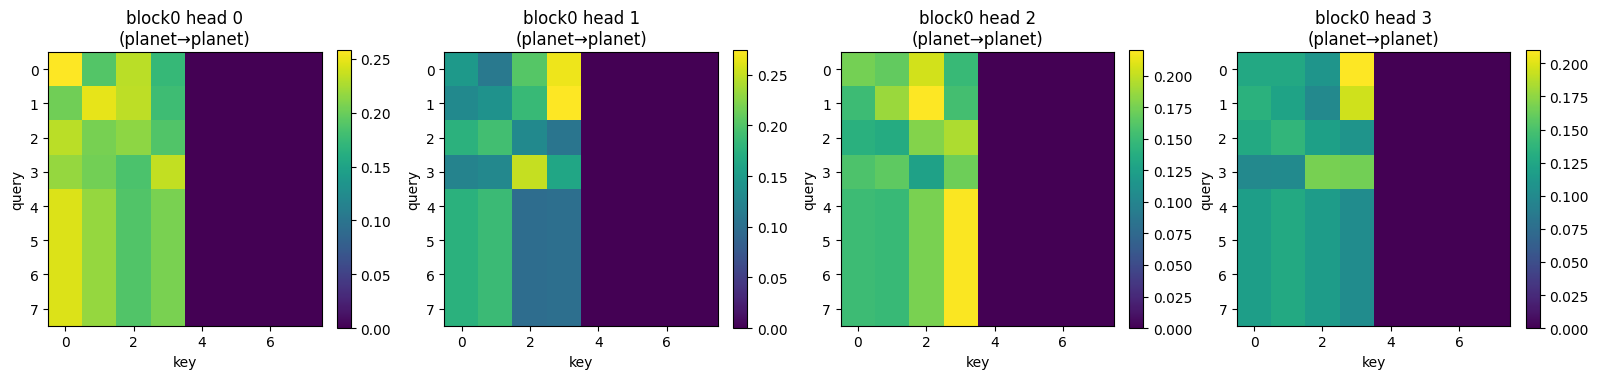

In [12]:
blk0 = net.blocks[0]
with torch.no_grad():
    z = blk0.norm1(x)
    B, T_, _ = z.shape
    qkv = blk0.attn.qkv(z).reshape(B, T_, 3, H, D//H).permute(2, 0, 3, 1, 4)
    q, k, _ = qkv[0], qkv[1], qkv[2]
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(D//H) + attn_bias
    scores = scores.masked_fill(kpm[:, None, None, :], float('-inf'))
    attn = torch.nan_to_num(torch.softmax(scores, dim=-1), nan=0.0)

fig, axs = plt.subplots(1, H, figsize=(4*H, 4))
for h_i in range(H):
    a = attn[0, h_i, :P_MAX, :P_MAX].numpy()
    im = axs[h_i].imshow(a, vmin=0, vmax=a.max(), cmap='viridis')
    axs[h_i].set_title(f'block0 head {h_i}\n(planet→planet)')
    axs[h_i].set_xlabel('key'); axs[h_i].set_ylabel('query')
    plt.colorbar(im, ax=axs[h_i], fraction=0.046)
plt.tight_layout(); plt.show()


## 10. Layer 7a — `src_head` + NO-OP

Her gezegen tokenından bir skaler logit. Geçersiz kaynaklar `source_mask` ile
`-inf` yapılır. Sonuna **öğrenilebilir** bir NO-OP logit eklenir → toplam `P+1`.

In [13]:
planet_tok_out = tokens[:, :P_MAX]            # (B, P, d)
global_tok_out = tokens[:, -1]                # (B, d)

with torch.no_grad():
    src_raw = net.src_head(planet_tok_out).squeeze(-1)             # (B, P)
    very_neg = torch.finfo(src_raw.dtype).min
    src_raw = src_raw.masked_fill(~batch['source_mask'], very_neg)
    noop = net.noop_logit.expand(src_raw.shape[0], 1)
    src_logits = torch.cat([src_raw, noop], dim=1)                  # (B, P+1)
    src_probs = torch.softmax(src_logits, dim=-1)

print('src_logits :', tuple(src_logits.shape))
print('source_mask:', batch['source_mask'][0].int().tolist())
print('src_probs  :', src_probs[0].numpy().round(4).tolist())
print('NO-OP prob :', float(src_probs[0, -1]))


src_logits : (1, 9)
source_mask: [1, 1, 0, 0, 0, 0, 0, 0]
src_probs  : [0.2912999987602234, 0.3034999966621399, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.40529999136924744]
NO-OP prob : 0.4052724540233612


## 11. Layer 7b — Pointer Attention (Target)

Her kaynak gezegen kendi `query`'sini, her hedef `key`'ini öğrenir; skor
`q · kᵀ / √d`. Self-target ve padded hedefler `-inf` ile maskelenir.

In [14]:
with torch.no_grad():
    q = net.tgt_query(planet_tok_out)                 # (B, P, d)
    k = net.tgt_key(planet_tok_out)                   # (B, P, d)
    tgt_logits = q @ k.transpose(-2, -1) / math.sqrt(D)

    eye = torch.eye(P_MAX, dtype=torch.bool)
    tgt_logits = tgt_logits.masked_fill(eye[None], very_neg)
    tgt_pad = ~batch['planet_mask']                   # True = pad
    tgt_logits = tgt_logits.masked_fill(tgt_pad[:, None, :], very_neg)

    tgt_probs = torch.softmax(tgt_logits, dim=-1)

print('tgt_logits:', tuple(tgt_logits.shape))
print('\nKaynak slot 0 için target dağılımı:')
print(tgt_probs[0, 0].numpy().round(4).tolist())
print('  • self-target prob (slot 0→0)            :', float(tgt_probs[0, 0, 0]))
print('  • padding hedeflere giden toplam olasılık:', float(tgt_probs[0, 0, 4:].sum()))


tgt_logits: (1, 8, 8)

Kaynak slot 0 için target dağılımı:
[0.0, 0.3221000134944916, 0.3605000078678131, 0.3174000084400177, 0.0, 0.0, 0.0, 0.0]
  • self-target prob (slot 0→0)            : 0.0
  • padding hedeflere giden toplam olasılık: 0.0


## 12. Layer 7c — `ship_head`

Her kaynak için sürekli "ne kadar gemi?" sorusu **kategorik** hale getirilir:
`n_ship_bins` farklı oran (default `0.1, 0.25, 0.5, 0.75, 1.0`).

In [15]:
with torch.no_grad():
    ship_logits = net.ship_head(planet_tok_out)        # (B, P, n_ship_bins)
    ship_probs = torch.softmax(ship_logits, dim=-1)

print('ship_logits:', tuple(ship_logits.shape))
print('Kaynak slot 0 ship-bin olasılığı:', ship_probs[0, 0].numpy().round(4).tolist())


ship_logits: (1, 8, 5)
Kaynak slot 0 ship-bin olasılığı: [0.10459999740123749, 0.20309999585151672, 0.09629999846220016, 0.2831000089645386, 0.31290000677108765]


## 13. Layer 7d — `value_head` (Critic)

Global token (encoder'dan sonra) bir 2-layer MLP'den geçer ve skaler `V(s)`
üretir. PPO/A2C için critic çıktısı.

In [16]:
with torch.no_grad():
    value = net.value_head(global_tok_out).squeeze(-1)  # (B,)
print('value :', value.tolist())


value : [-0.08562508225440979]


## 14. Tek Komutla Forward + `act()` ile Aksiyon

Buraya kadar tüm adımlar `OrbitWarsPolicy.forward` içinde sırayla çalışan kodun aynısı.
Şimdi resmi API ile karşılaştıralım:

In [17]:
with torch.no_grad():
    out = net(**batch)
    action = net.act(out, deterministic=False)

# Ara hesaplarla aynı mı?
print('forward src_logits == manual?', torch.allclose(out.src_logits, src_logits))
print('forward tgt_logits == manual?', torch.allclose(out.tgt_logits, tgt_logits))
print('forward value      == manual?', torch.allclose(out.value, value))
print()
print('Sampled action:')
for k, v in action.items():
    print(f'  {k:9s} : {v.tolist()}')


forward src_logits == manual? True
forward tgt_logits == manual? True
forward value      == manual? True

Sampled action:
  src       : [0]
  tgt       : [1]
  ship_bin  : [2]
  is_noop   : [False]
  log_prob  : [-4.7064313888549805]


## 15. `decode_action` — Slot → Env Aksiyonu

Model **slot index** seçer; gerçek env aksiyonu için slot → planet_id eşlemesi
ve `compute_launch` ile açı hesabı yapılır.

In [18]:
from feature_extraction import parse_planets

src_slot = int(action['src'][0])
tgt_slot = int(action['tgt'][0])
ship_bin = int(action['ship_bin'][0])
is_noop  = bool(action['is_noop'][0])

parsed_planets = parse_planets(toy_state)
env_action = decode_action(
    obs, src_slot, tgt_slot, ship_bin,
    planets=parsed_planets, angular_velocity=0.05, no_op=is_noop,
)
print(f'src_slot={src_slot}  tgt_slot={tgt_slot}  ship_bin={ship_bin}  noop={is_noop}')
print('Env aksiyonu:', env_action)


src_slot=0  tgt_slot=1  ship_bin=2  noop=False
Env aksiyonu: [0, 0.4748615048784556, 50]


## 16. Shape Özeti

| Stage | Tensor | Shape |
|---|---|---|
| Input | `planet_feats` | `(B, P, 15)` |
| Input | `fleet_feats` | `(B, F, 11)` |
| Input | `global_feats` | `(B, 12)` |
| Input | `edge_bias` | `(B, T, T, 5)` |
| After projections | `x` | `(B, T, d)` |
| Edge proj | `attn_bias` | `(B, H, T, T)` |
| Padding mask | `kpm` | `(B, T)` |
| After transformer | `tokens` | `(B, T, d)` |
| Head | `src_logits` | `(B, P+1)` |
| Head | `tgt_logits` | `(B, P, P)` |
| Head | `ship_logits` | `(B, P, k_bins)` |
| Head | `value` | `(B,)` |

**Özet:** Heterojen feature'lar tek `d_model` uzayına projekte → type-embed ile ayırt edilir →
edge bias ile geometrik prior attention'a enjekte → maskelenmiş self-attention bloklarından geçer →
dört ayrı head policy faktörlerini ve value'yu üretir → `act()` örnekler → `decode_action`
env aksiyonuna çevirir.
